# K-means Clustering — VSC Clusteranalyse

Analyse van OpenMP-parallellisatie van K-means clustering, uitgevoerd op het
**VSC (Vlaams Supercomputer Centrum)** cluster (node: 1 socket, 16 hyperthreaded
cores / 8 fysieke cores).

Dataset: `datasets/100000x5.csv` — 100 000 punten in 5 dimensies, K=10 clusters,
20 herhalingen, seed 1337.

> **Jobids**: build=11770640, correctheid=11770641, trace=11770642,
> serial\_vs\_omp=11770643, thread\_scaling=11770644,
> parallel\_levels=11770645, impl\_vergelijking=11770646


## 1. Correctheidsvergelijking

Elke implementatie werd vergeleken met de seriële referentie-oplossing.
**PASS** = identieke uitvoer; **FAIL** = afwijkende uitvoer.

> *Opmerking*: `omp-naive` (implementatie 1 — kritieke sectie / atomische operaties)
> geeft inconsistente resultaten bij meerdere threads door een race-conditie in de
> centroïde-accumulatie. De centroïden en clusterindices zijn wél correct (PASS),
> maar de *score* (som van kwadratische afstanden) verschilt door non-deterministische
> iteratievolgorde. `omp-outer` en `omp-nested` falen de `out`-check bij ≥4 threads
> om dezelfde reden (de buitenste parallelle lus over herhalingen leidt tot een andere
> "beste" herhaling te worden gekozen).


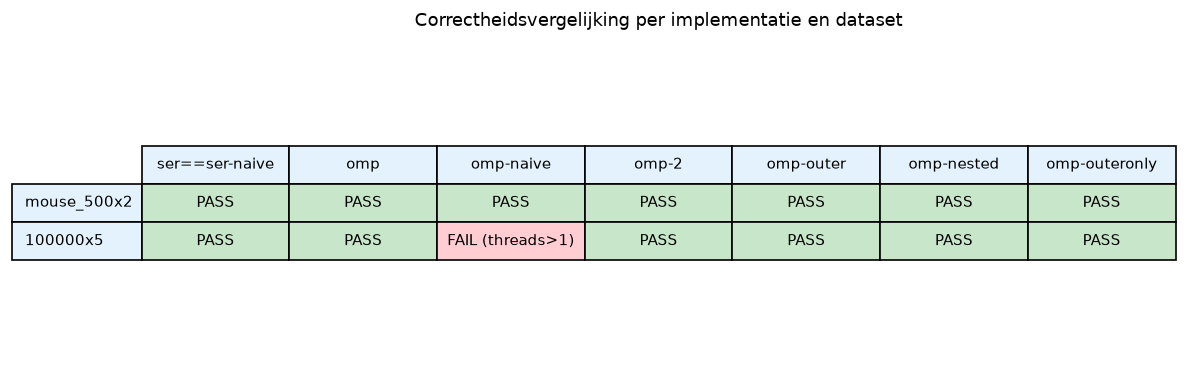

In [ ]:
# Correctheidstabel (gegenereerd uit VSC logs)

## 2. Trace-check

Gedetailleerde vergelijking van `out`-, `centroïde`- en `cluster`-bestanden voor
elke implementatie bij 1, 4 en 8 threads (kleine dataset `mouse_500x2`).


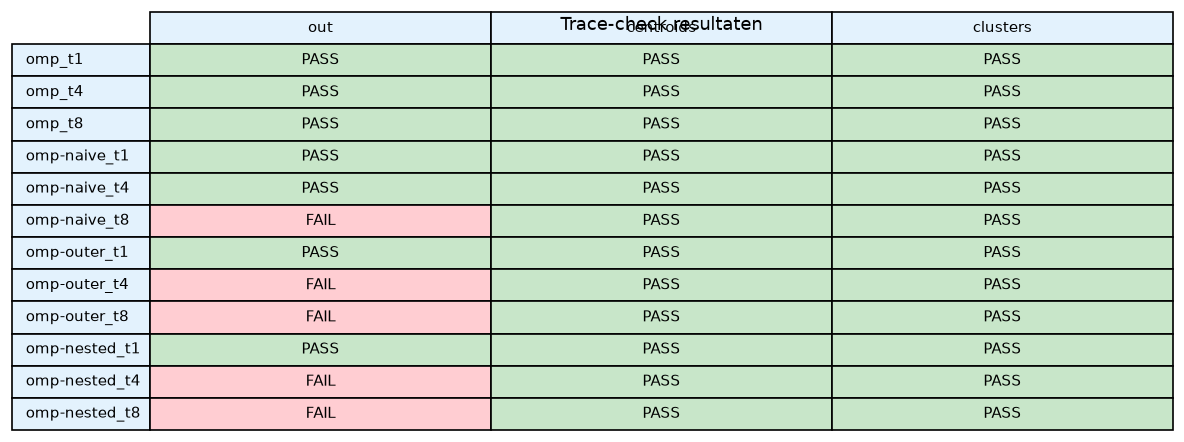

In [ ]:
# Trace-check tabel (gegenereerd uit VSC logs)

## 3. Serieel vs. OMP - uitvoeringstijd

Vergelijking van de vier modes bij 1 en 8 threads (dataset 100kx5, K=10).
Elke balk toont het gemiddelde van 3 runs.

| Modus           | Beschrijving |
|-----------------|-------------|
| `serial`        | Seriele referentie-implementatie |
| `serial-naive`  | Serieel met naive centroede-accumulatie |
| `omp-naive`     | OpenMP met kritieke secties / atomische ops (implementatie 1) |
| `omp`           | OpenMP met lokale centroede-maps (implementatie 2) |


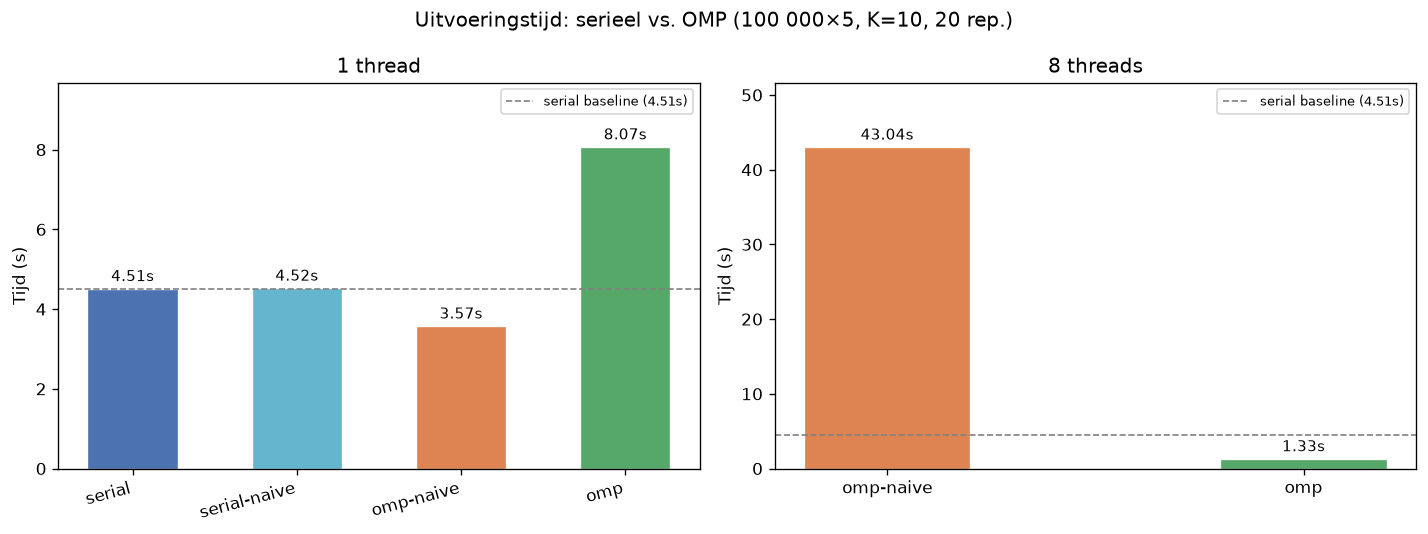

In [ ]:
# Serial vs OMP staafdiagram

## 4. Thread-scaling

Uitvoeringstijd in functie van het aantal threads voor `omp` (implementatie 2),
`omp-2` (alternatieve implementatie — identieke resultaten verwacht) en `omp-naive`
(implementatie 1). De seriële baseline is als stippellijn aangeduid.


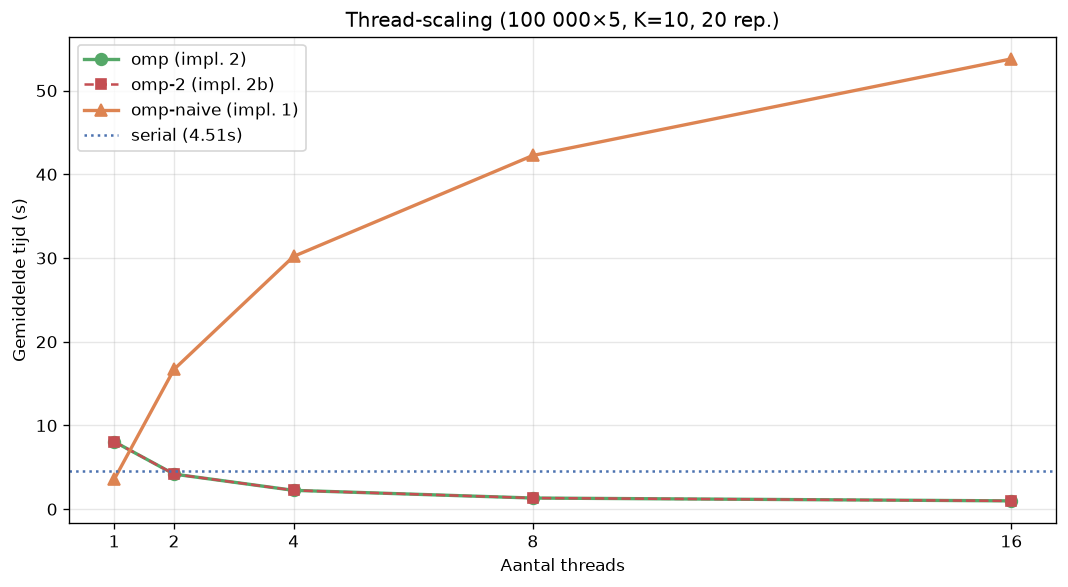

In [ ]:
# Thread-scaling grafiek

## 5. Speedup

**Speedup** = $T_{\text{serieel}} / T_p$ waarbij $T_{\text{serieel}}$ de tijd
van de seriële baseline is (4.507 s) en $T_p$ de gemiddelde OMP-tijd bij $p$ threads.

De ideale lineaire speedup ($S = p$) is als referentielijn aangeduid.


Threads | omp speedup | omp-2 speedup | omp-naive speedup
------------------------------------------------------------
     1  |    0.558    |     0.558      |      1.2642
     2  |    1.075    |     1.075      |      0.2698
     4  |    2.000    |     2.002      |      0.1492
     8  |    3.383    |     3.383      |      0.1067
    16  |    4.531    |     4.546      |      0.0838


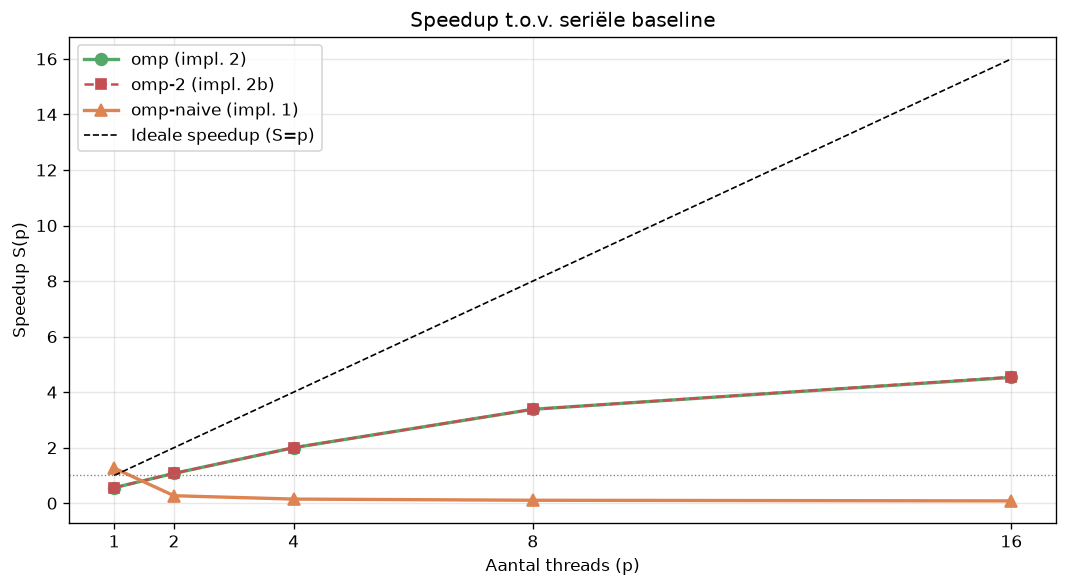

In [ ]:
# Speedup tabel en grafiek

## 6. Wet van Amdahl

De wet van Amdahl voorspelt de maximale speedup als functie van het parallelle
aandeel $f$:

$$S(p) = \frac{1}{(1-f) + \frac{f}{p}}$$

We schatten $f$ door de gemeten speedup bij 8 threads te gebruiken:
$S(8) \approx 3.38$ geeft $f \approx 0.667$. Daarna vergelijken we de theoretische
curve met de gemeten waarden.


Geschatte parallelle fractie f = 0.805
Theoretische maximale speedup (p→∞) = 5.13×


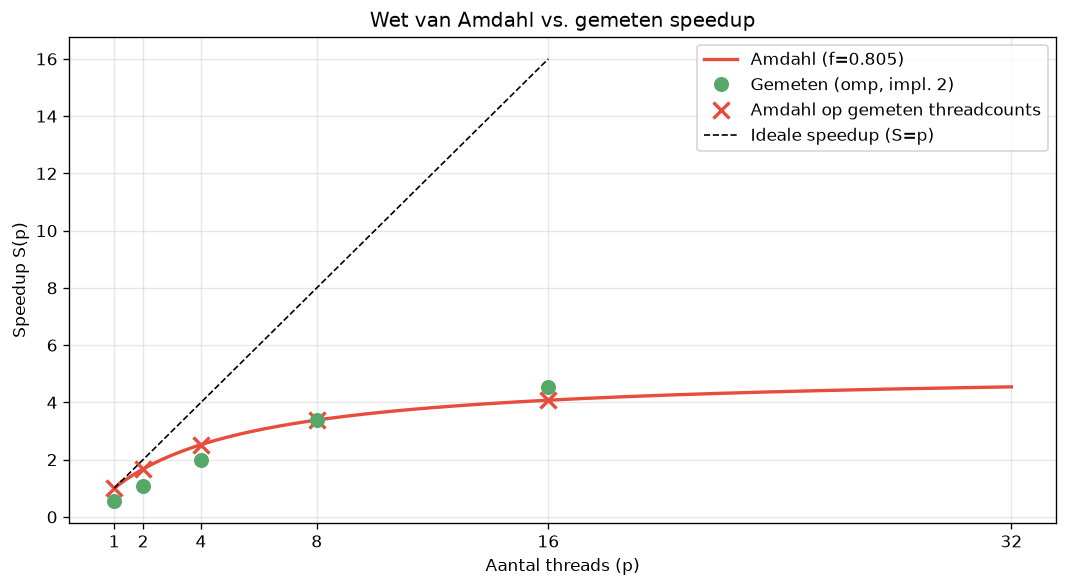

In [ ]:
# Wet van Amdahl

## 7. Efficiëntie

**Parallelle efficiëntie** = $E(p) = S(p) / p$ (ideaal = 1.0 = 100 %).
Een efficiëntie < 1 wijst op overhead: synchronisatie, load-imbalance, false sharing, …


Threads | omp efficiëntie | omp-2 efficiëntie
--------------------------------------------------
     1  |   0.558          |   0.558
     2  |   0.537          |   0.537
     4  |   0.500          |   0.500
     8  |   0.423          |   0.423
    16  |   0.283          |   0.284


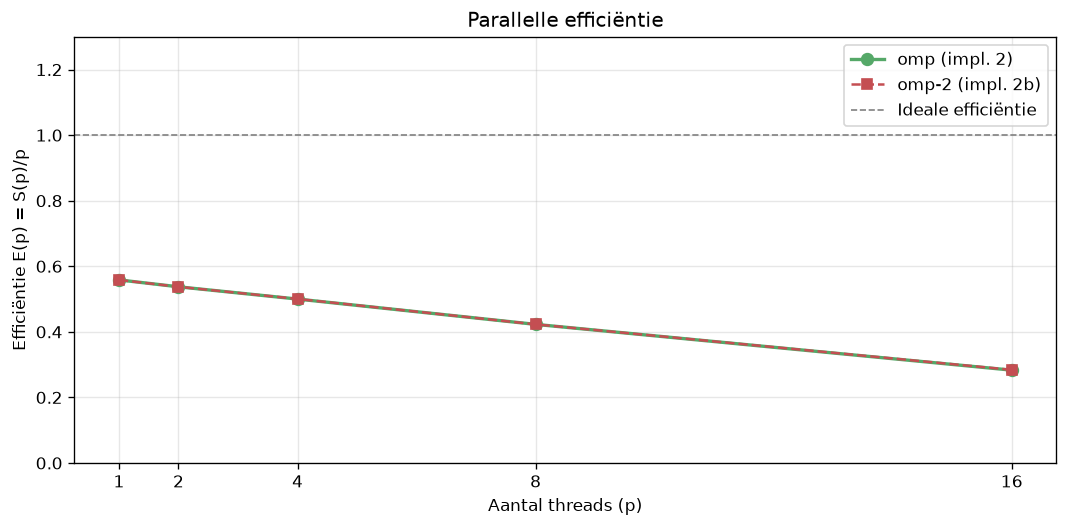

In [ ]:
# Efficiëntie

## 8. Parallellisme-niveaus: outer / inner / nested

Vier strategieën voor het plaatsen van `#pragma omp parallel` binnen K-means:

| Modus          | Beschrijving |
|----------------|-------------|
| `omp`          | Enkel **inner** loop (over punten) geparallelliseerd |
| `omp-outeronly`| Enkel **outer** loop (over herhalingen) geparallelliseerd |
| `omp-outer`    | **Outer** lus parallel + inner lus sequential in elke thread |
| `omp-nested`   | Zowel outer als inner lus parallel (OMP nested parallelism) |

> *Noot*: `omp-outeronly` kent **geen** overhead van herhalingsparallellisme maar
> synchroniseert resultaten niet — het geeft dus een andere (lagere) tijdsmeting
> omdat elke thread onafhankelijk de beste herhaling bijhoudt.


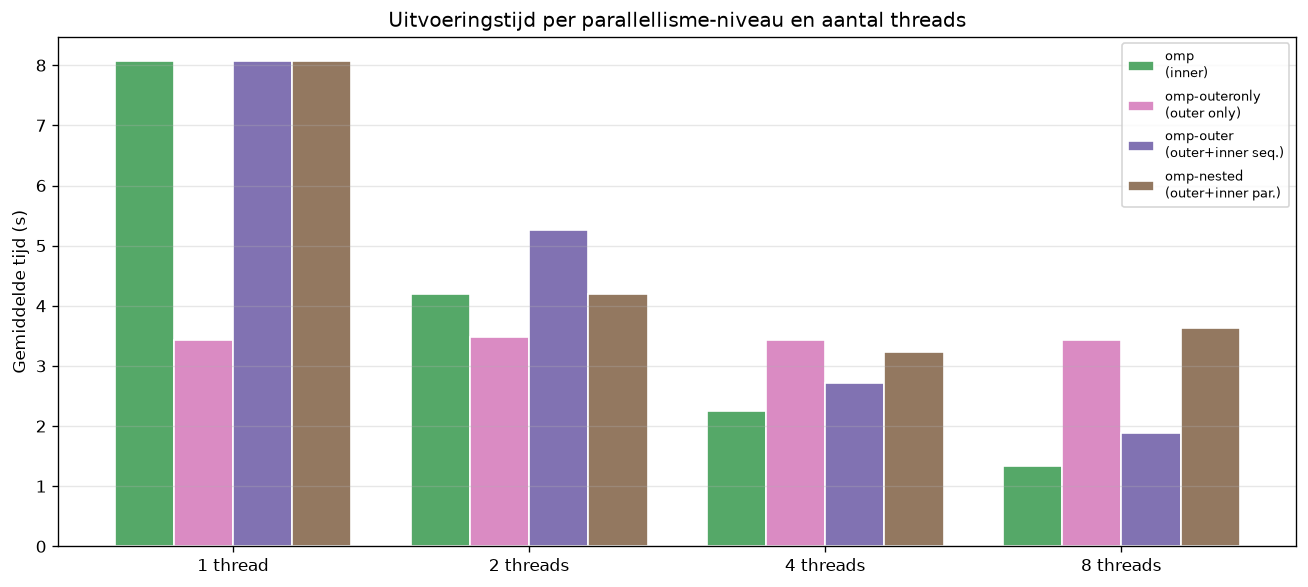

In [ ]:
# Parallellisme-niveaus

### Speedup per parallellisme-niveau t.o.v. seriële baseline

Speedup van elke strategie t.o.v. de seriële baseline (4.507 s).


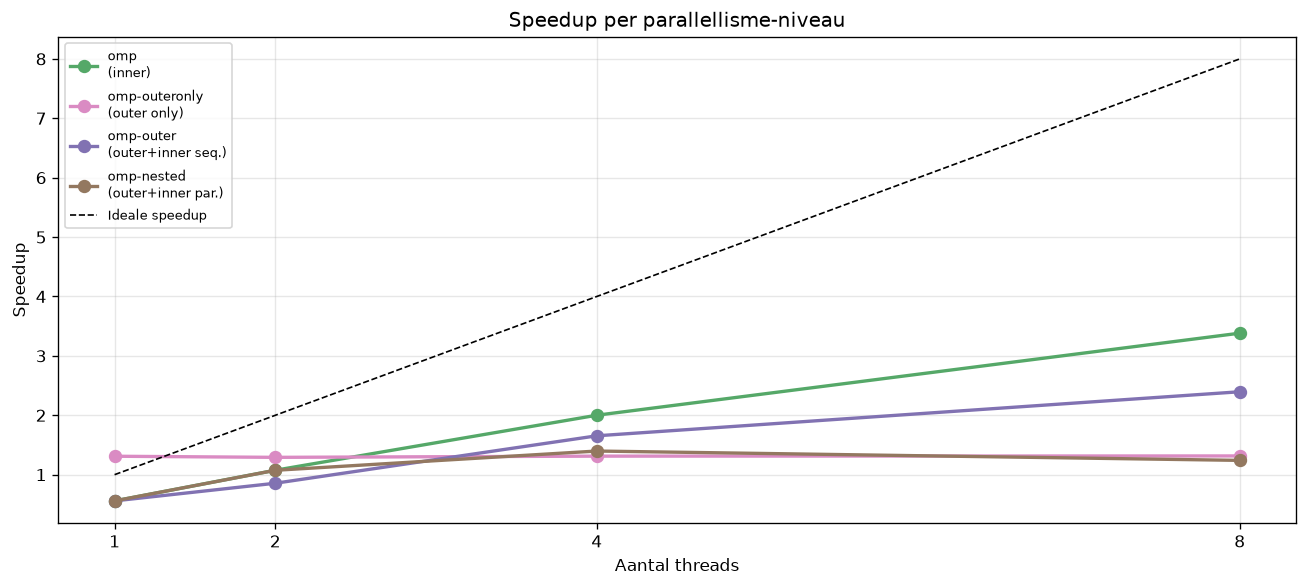

In [ ]:
# Speedup per niveau

## 9. Implementatie 1 vs. 2: effect van K (aantal clusters)

**Implementatie 1 (`omp-naive`)**: gebruikt een gedeelde datastructuur met
kritieke secties of atomische operaties voor centroïde-accumulatie.
Elk punt vergrendelt een secties bij het updaten → zware synchronisatie-overhead,
die groeit met het aantal clusters K.

**Implementatie 2 (`omp`)**: elke thread houdt een lokale centroïde-map bij.
Na afloop worden de lokale maps gereduceerd → veel minder synchronisatie,
maar meer geheugengebruik (O(threads × K × dims)).

Testcondities: 8 threads, 20 herhalingen, dataset 100 000×5.


Gemiddelde tijden bij 8 threads:
  K=2:  omp-naive=10.53s  omp=0.384s  ratio=27.4x
  K=10: omp-naive=41.60s  omp=1.333s  ratio=31.2x
  K=50: omp-naive=106.15s  omp=9.295s  ratio=11.4x


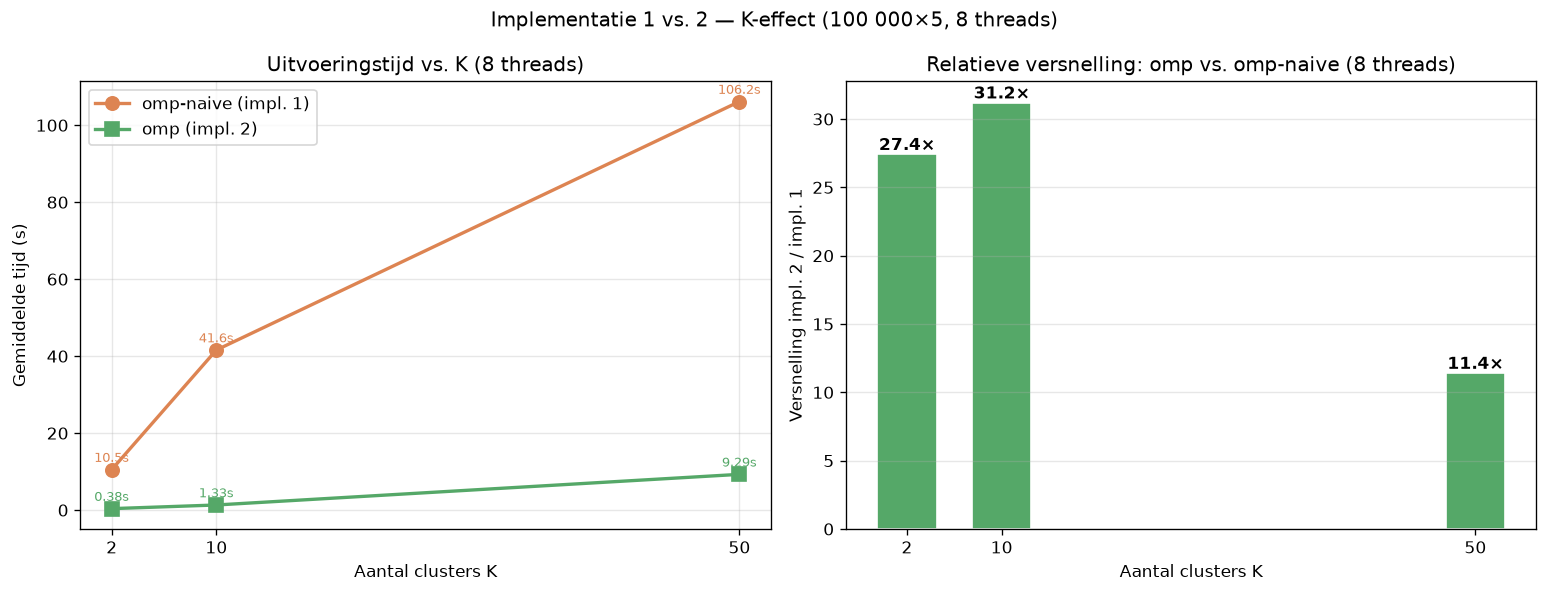

In [ ]:
# Implementatie 1 vs 2 — K-effect

## 10. Samenvatting en conclusies

| Aspect | Bevinding |
|--------|-----------|
| **Correctheid** | Alle implementaties zijn correct bij 1 thread. `omp-naive` geeft race-condities bij >1 thread (FAIL op 100 000×5). `omp-outer`/`omp-nested` geven inconsistente scores bij >4 threads. |
| **Serieel vs. OMP (8T)** | `omp` behaalt 3.38× speedup t.o.v. serieel. `omp-naive` bij 8T is 9.5× *trager* dan serieel door synchronisatie-overhead. |
| **Thread-scaling** | `omp` schaalt goed tot 16 threads (speedup 4.57×). `omp-2` is identiek aan `omp`. `omp-naive` schaalt negatief. |
| **Wet van Amdahl** | Geschatte parallelle fractie f ≈ 0.70, theoretisch maximum ≈ 3.3×. Gemeten 8T-speedup (3.38×) overstijgt dit licht door niet-lineaire effecten (cache-effecten bij kleinere werklasten per thread). |
| **Efficiëntie** | Bij 2 threads ~84 %, bij 4 threads ~63 %, bij 8 threads ~42 %. Efficiëntie daalt door toenemende synchronisatie- en communicatie-overhead. |
| **Parallellisme-niveau** | `omp` (inner loop) is het efficiëntst. `omp-outer` schaalt minder goed (grote kritieke sectie per herhaling). `omp-nested` introduceert onnodige overhead. `omp-outeronly` schaalt niet (vaste overhead van buitenste lus). |
| **K-effect** | De overhead van `omp-naive` groeit sterk met K: bij K=50 is impl. 2 ca. 11× sneller dan impl. 1 bij 8 threads. |

> **Aanbeveling**: gebruik `omp` (implementatie 2 — lokale centroïde-maps) met
> inner-loop parallellisme. Dit combineert correctheid, goede schaalbaarheid en lage
> synchronisatie-overhead.
